# Inferenece example to classify the images into: PA or L

## Import libraries

In [2]:
import torch
from torch.utils.data import Dataset, DataLoader
import pandas as pd
from PIL import Image
import os
from torchvision import transforms
import matplotlib.pyplot as plt

import torchxrayvision as xrv
import skimage, torch, torchvision
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Load an image and perform transformations

Max value before normalization: 65535
Min value before normalization: 0
Image size: (224, 224)
--------------------------------------
Max value after normalization: 1024.0
Min value after normalization: -1024.0
Image size: (1, 224, 224)


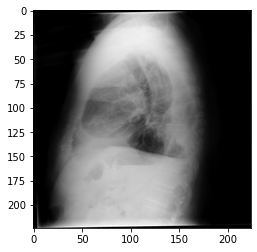

In [6]:
# PA image
#datapath = './PadChest224/images/320880373641364002317703283884861936134_khvmrz.png' 

# L image
datapath = './PadChest224/images/3137231742710829928-247610802266403640553_km0qf9.png' 

# Read the image
img = skimage.io.imread(datapath)

# Statistics before normalization
print('Max value before normalization:',img.max())
print('Min value before normalization:',img.min())
print('Image size:',img.shape)
print('--------------------------------------')

# Transforms: Normalize
img = xrv.datasets.normalize(img, maxval = 65535, reshape = True) # convert 16-bit image to [-1024, 1024] range

# Statistics after normalization
print('Max value after normalization:',img.max())
print('Min value after normalization:',img.min())
print('Image size:',img.shape)

# Transforms: Center Crop and Resize
transform = transforms.Compose([xrv.datasets.XRayCenterCrop(), xrv.datasets.XRayResizer(224)])
img = transform(img)

#Visualize the image
visualize_image = torch.from_numpy(img).unsqueeze(0)
plt.imshow(visualize_image[0][0], cmap='gray')

## Load the model and run the inference

In [7]:
# Load the model
model_resnet18 = torch.load(os.path.join('./Models/','resnet18_xrayView_PA_L.pth'), map_location = torch.device(DEVICE))
model_resnet18 = model_resnet18.eval()

#Run the inference
input_img = torch.from_numpy(img).to(DEVICE)
outputs = model_resnet18(input_img[None,...])

## Represent results: option 1

In [8]:
#Obtain the probabilities of each class
probs = torch.nn.functional.softmax(outputs, dim=1)[0] * 100

PA_probs = probs.data.cpu().numpy()[0]
L_probs = probs.data.cpu().numpy()[1]

# determine the most probable view
maxValue = max(PA_probs, L_probs )
if maxValue == PA_probs:
    mostProbableView = "PA"
elif maxValue == L_probs:
    mostProbableView = "L"
    
print(f"The view is {mostProbableView} with a probability of {maxValue} %" )

The view is L with a probability of 99.99989318847656 %


## Represent results: option 2

In [9]:
#Obtain the probabilities of each class
probs = (torch.nn.functional.softmax(outputs, dim=1)[0] * 100).tolist()

# determine the most probable view
view_labels = ["PA", "L"]
mostProbableView = view_labels[probs.index(max(probs))]

print(f"The view is {mostProbableView} with a probability of {max(probs)} %" )

The view is L with a probability of 99.99989318847656 %
